# Manchester Housing – Exploratory Data Analysis

**Module:** COM7024 Programming for Data Analytics · **Student ID:** 25361939

## Objective
Estate Management Plc wants an evidence base for the Manchester housing
market. This notebook performs a reproducible exploratory data analysis
(EDA) that answers three questions:

1. **Waterfront** – how do waterfront properties differ from the rest of
   the market?
2. **Floor space** – how is living floor space related to price?
3. **Year built** – is the construction year (`built`) correlated with
   price?

## How this notebook is organised
The reusable logic lives in the `src` package (data ingestion,
preprocessing, statistics, charts); this notebook *orchestrates* it and
explains every step. This separation keeps the notebook short, makes the
code testable (`tests/`) and lets the same pipeline run from the command
line (`python -m src.pipeline.run_pipeline`).

| Section | Content |
|---|---|
| 0 | Environment set-up |
| 1–2 | Data ingestion and type correction |
| 3–4 | Initial statistics, distributions and data-quality audit |
| 5–6 | Pre-processing and evidence of improvement |
| 7 | Correlation overview |
| 8–10 | Focused investigations |
| 11–12 | Saved artifacts, summary, limitations and next steps |

## 0. Environment set-up

**What happens:** the project root is added to Python's search path so
that `src` can be imported whether the notebook is started from the
project folder or from `notebooks/`. Library versions are printed for
reproducibility.

In [ ]:
# Standard library imports.
import sys
from pathlib import Path

# Locate the project root (the folder that contains "src").
PROJECT_ROOT = Path.cwd()
while (not (PROJECT_ROOT / "src").is_dir()
       and PROJECT_ROOT != PROJECT_ROOT.parent):
    PROJECT_ROOT = PROJECT_ROOT.parent
# Make "import src" work from any working folder.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Third-party imports.
import matplotlib  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import scipy  # noqa: E402
import seaborn as sns  # noqa: E402
import statsmodels  # noqa: E402
from IPython.display import Image, display  # noqa: E402

# Project imports (the reusable pipeline components).
from src import config  # noqa: E402
from src.components import visualisation as viz  # noqa: E402
from src.components.data_ingestion import DataIngestion  # noqa: E402
from src.components.data_preprocessing import (  # noqa: E402
    DataPreprocessor, audit_quality, before_after_comparison, correct_types)
from src.components.eda_analysis import (  # noqa: E402
    analyse_built_price, analyse_floor_space, analyse_waterfront)
from src.utils import save_table, summary_table  # noqa: E402

# Readable table output.
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Record the software versions used for this analysis.
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | "
      f"numpy {np.__version__} | scipy {scipy.__version__} | "
      f"statsmodels {statsmodels.__version__} | "
      f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")
print("Project root:", PROJECT_ROOT.name)

Python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | scipy 1.18.1 | statsmodels 0.15.0 | matplotlib 3.11.2 | seaborn 0.13.2
Project root: Manchester_housing_Data_Analysis


## 1. Data ingestion

**What happens:** `DataIngestion` looks in `data/raw/` for the file
`Manchester_house_Dataset*.csv` and reads it with `utf-8-sig` encoding,
which strips an invisible byte-order mark from the first column name.
Errors are raised as a `CustomException` that names the file and line,
and every step is written to `logs/`.

In [ ]:
# Load the raw dataset exactly as stored on disk.
raw = DataIngestion().load()
print("Shape (rows, columns):", raw.shape)
raw.head()

Shape (rows, columns): (19999, 15)


,Unnamed: 0,id,price,bedrooms,bathrooms,sqft_living,sqft_total,floors,waterfront,view,condition,grade,built,renovated,living_area
0,0,7129300520,221900,3.00,1.00,1180,5650,1.00,0,0,3,7,1955,0,1340
1,1,6414100192,538000,3.00,2.25,2570,7242,2.00,0,0,3,7,1951,1991,1690
2,2,5631500400,180000,2.00,1.00,770,10000,1.00,0,0,3,6,1933,0,2720
3,3,2487200875,604000,4.00,3.00,1960,5000,1.00,0,0,5,7,1965,0,1360
4,4,1954400510,510000,3.00,2.00,1680,8080,1.00,0,0,3,8,1987,0,1800


**Result:** 19,999 property sales and 15 columns were loaded. Each row is
one sale; `price` is the target of interest, the remaining columns
describe the property (size, rooms, quality ratings, year built,
renovation year and neighbourhood floor space).

## 2. Data types

**What happens:** pandas guesses every column as numeric. That is
technically valid but semantically wrong for several variables, and the
type decides which statistics are meaningful. `correct_types()`:

* drops `Unnamed: 0` (an exported row index),
* stores `id` as text (a label – arithmetic on it is meaningless),
* stores `waterfront` as Boolean,
* stores `view`, `condition` and `grade` as **ordered categoricals**
  (ordered, but the distance between levels is not fixed).

In [ ]:
# Apply the type corrections and compare the data types side by side.
df = correct_types(raw)
pd.DataFrame({"before": raw.dtypes.astype(str),
              "after": df.dtypes.astype(str)}).fillna("(dropped)")

,before,after
Unnamed: 0,int64,(dropped)
bathrooms,float64,float64
bedrooms,float64,float64
built,int64,int64
condition,int64,category
floors,float64,float64
grade,int64,category
id,int64,str
living_area,int64,int64
price,int64,int64


**Result:** the dataset now has 14 analytical columns with types that
match their meaning. Ordered categoricals keep the natural order of the
ratings, so sorting and grouping behave correctly.

## 3. Initial descriptive statistics (all variables)

**What happens:** `summary_table()` extends pandas' `describe()` with
skewness, kurtosis and missing counts for every numeric variable, and
frequency counts are shown for the categorical ones.

In [ ]:
# Descriptive statistics for every numeric variable (raw data).
initial_stats = summary_table(df, config.NUMERIC_COLS)
initial_stats.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,missing
price,"19,999.00","535,468.02","365,956.63","75,000.00","317,000.00","449,950.00","640,000.00","7,700,000.00",4.12,36.64,0
bedrooms,"19,986.00",3.37,0.93,1.00,3.00,3.00,4.00,33.00,2.15,53.03,13
bathrooms,"19,989.00",2.07,0.76,0.50,1.50,2.00,2.50,8.00,0.55,1.34,10
sqft_living,"19,999.00","2,057.89",905.64,290.00,"1,420.00","1,900.00","2,510.00","13,540.00",1.52,5.82,0
sqft_total,"19,999.00","15,607.00","41,771.19",520.00,"5,350.00","7,819.00","11,000.00","1,651,359.00",13.04,286.44,0
floors,"19,999.00",1.44,0.52,1.00,1.00,1.00,2.00,3.50,0.68,-0.51,0
built,"19,999.00","1,967.95",28.32,"1,900.00","1,950.00","1,969.00","1,991.00","2,015.00",-0.45,-0.63,0
renovated,"19,999.00",90.81,415.95,0.00,0.00,0.00,0.00,"2,015.00",4.36,17.03,0
living_area,"19,999.00","1,974.29",675.26,399.00,"1,490.00","1,830.00","2,338.00","6,210.00",1.12,1.66,0


In [ ]:
# Frequency counts of the categorical variables.
for col in config.ORDINAL_COLS + ["waterfront"]:
    print(f"{col:<11}", df[col].value_counts().sort_index().to_dict())

view        {0: 17973, 1: 317, 2: 918, 3: 482, 4: 309}
condition   {1: 30, 2: 172, 3: 12430, 4: 5667, 5: 1700}
grade       {1: 1, 3: 3, 4: 29, 5: 241, 6: 2029, 7: 8656, 8: 5359, 9: 2233, 10: 998, 11: 352, 12: 85, 13: 13}
waterfront  {False: 19840, True: 159}


**Results and interpretation**

* **Price is strongly right-skewed** (skewness 4.12, kurtosis 36.6). The
  mean (535,468) is 19% above the median (449,950), so medians and
  rank-based methods are more representative than means.
* **`bedrooms`** has an impossible maximum of **33**, and `bedrooms` (13)
  and `bathrooms` (10) contain missing values.
* **`sqft_total`** (plot area) is extremely skewed (13.04).
* **`renovated`** has a meaningless mean of 90.81 because `0` encodes
  "never renovated" for 95.5% of properties.
* Waterfront properties are **rare: 159 of 19,999 (0.8%)**, and 89.9% of
  properties have a view rating of 0. Grades cluster at 7–8 (70% of
  sales) and condition at 3 (62%).

### 3.1 Distributions

**What happens:** a histogram grid shows the shape of every numeric
variable at once, followed by bar charts of the categorical variables.

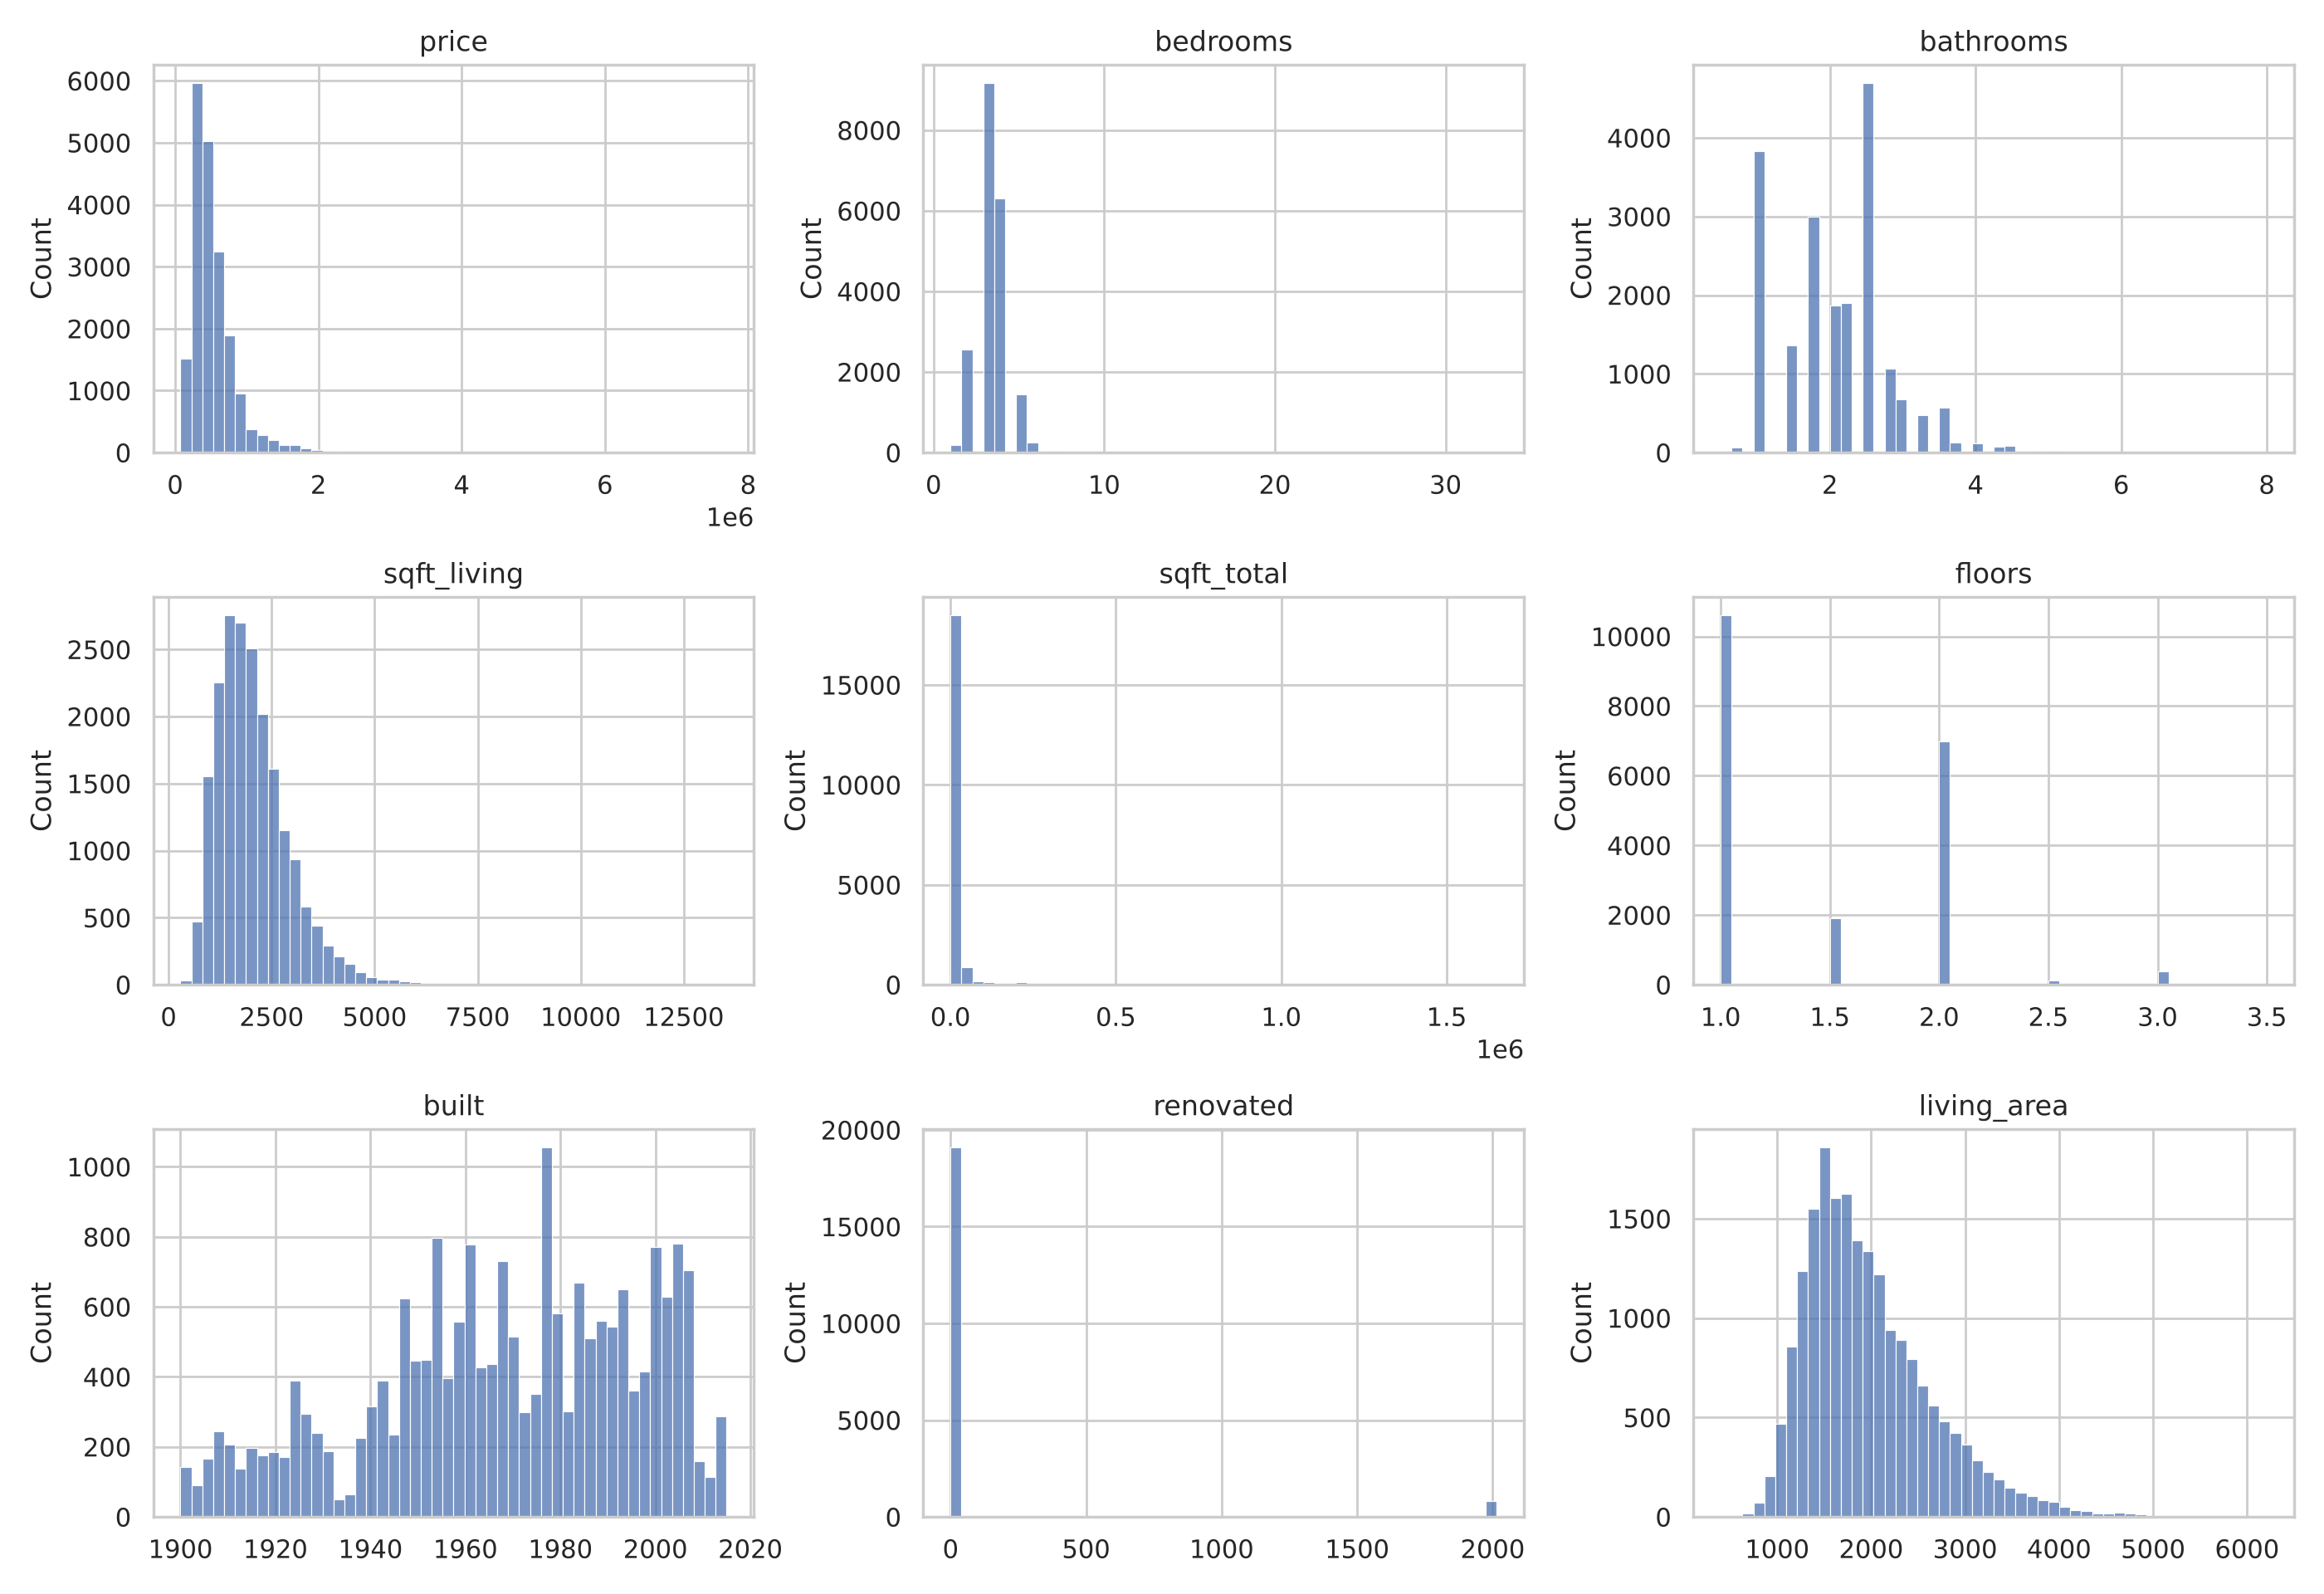

In [ ]:
# Histogram of every numeric variable.
display(Image(viz.plot_numeric_distributions(df, config.NUMERIC_COLS)))

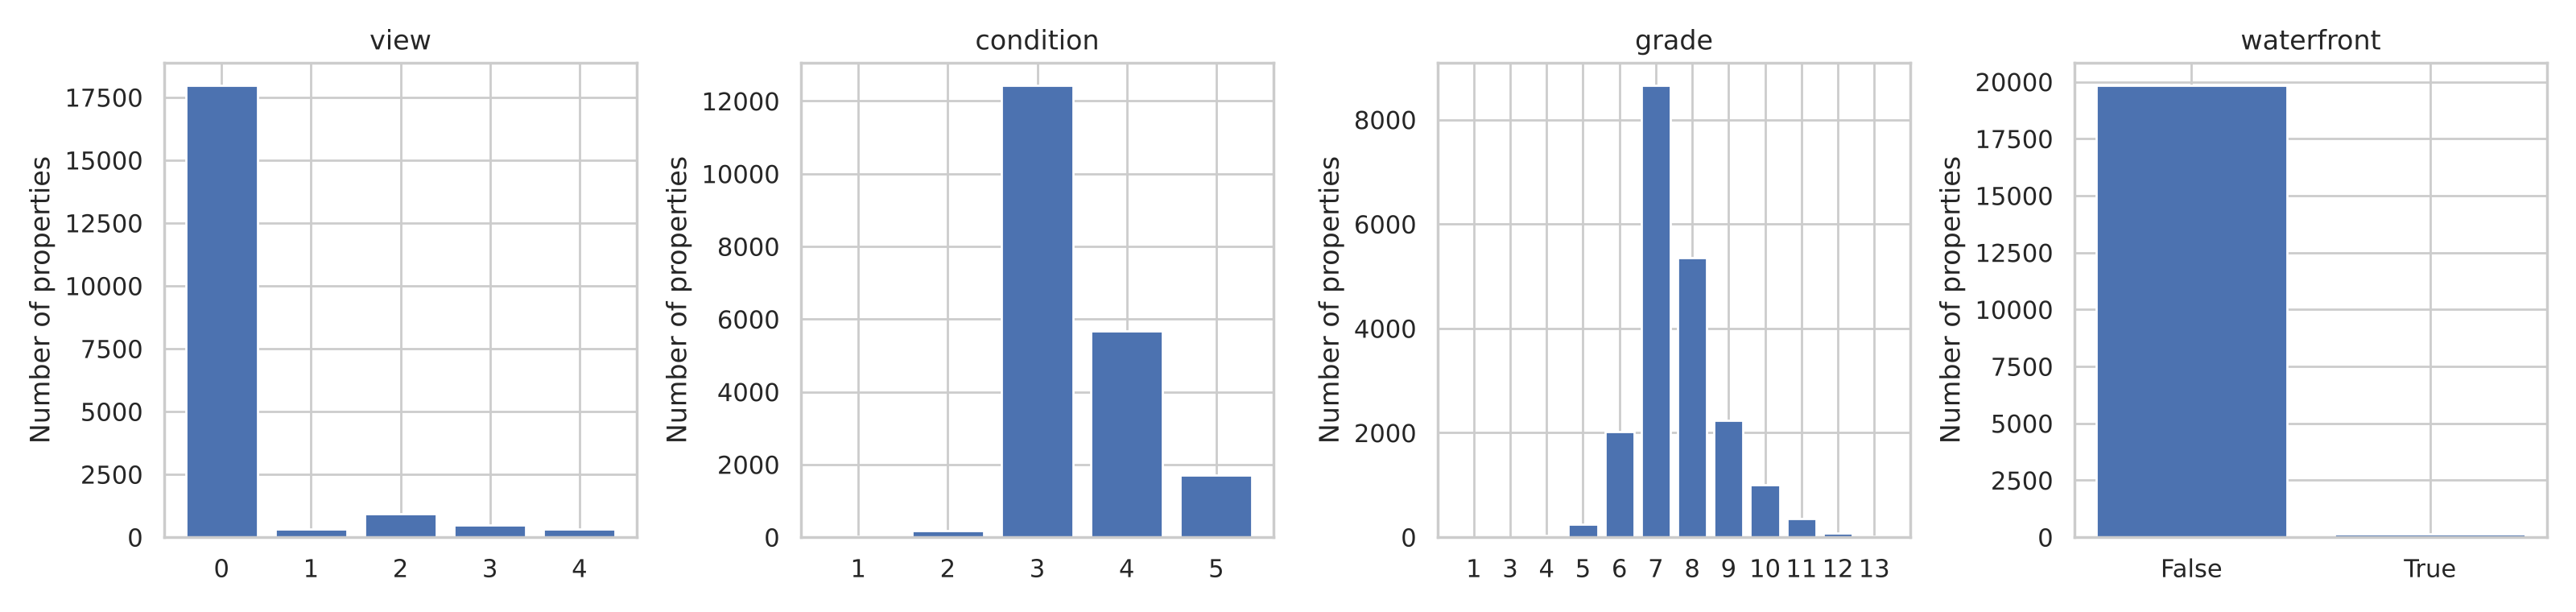

In [ ]:
# Frequency of each categorical variable.
display(Image(viz.plot_categorical_counts(
    df, config.ORDINAL_COLS + ["waterfront"])))

**Interpretation:** `price`, `sqft_living`, `sqft_total` and
`living_area` all have long right tails – a few very large or expensive
properties. This motivates log transformations later. `renovated` is a
spike at 0 plus a small cluster of years between 1934 and 2015, confirming the coding
problem. The categorical charts show how unbalanced the sample is:
waterfront and high-view properties form a small minority, so any
comparison involving them carries more uncertainty.

## 4. Data-quality audit

**What happens:** before changing anything, every potential problem is
*measured*, so each pre-processing decision is justified by evidence.
Price outliers are detected with Tukey's 1.5 × IQR rule.

In [ ]:
# Count each data-quality issue.
audit = audit_quality(df)
pd.Series(audit, name="count").to_frame()

,count
missing_bedrooms,13
missing_bathrooms,10
exact_duplicates,2
repeated_ids,171
implausible_bedrooms,1
living_gt_plot,453
never_renovated,19089
price_outliers,1052
waterfront_price_outliers,98
waterfront_total,159


**Results and decisions**

| Finding | Decision |
|---|---|
| 2 exact duplicate rows | remove |
| 171 repeated ids with different prices | keep – repeat sales; no date to choose between them |
| 1 record with 33 bedrooms (1,620 sq ft) | set to missing, then impute |
| 23 missing room counts (0.1%) | impute with the median of the same grade |
| 453 homes with floor space > plot | keep – plausible for multi-storey homes |
| `renovated = 0` for 19,089 homes | split into a flag and a true year |
| **1,052 price outliers, 98 of 159 waterfront homes (62%)** | **flag, do not remove** |

The last row is the key judgement: deleting IQR outliers would delete most
waterfront properties and bias the very question the manager asked.

## 5. Pre-processing

**What happens:** `DataPreprocessor.run()` applies the decisions above in
order and adds derived features: `log_price`, `log_sqft_living`,
`price_per_sqft`, `decade_built` and a `price_outlier` flag.

In [ ]:
# Clean the data and show the decision log.
result = DataPreprocessor().run(df)
clean = result.clean
for step in result.decision_log:
    print("•", step)
print("Clean shape:", clean.shape)

• Exact duplicates removed: 2
• Implausible bedroom values set to missing: 1
• bedrooms: 14 missing values imputed (grade-group median)
• bathrooms: 10 missing values imputed (grade-group median)
• renovated split into is_renovated (bool) and renovated_year (NaN if never)
• Added log_price, log_sqft_living, price_per_sqft, decade_built, price_outlier flag
Clean shape: (19997, 20)


## 6. Post-processing statistics – evidence of improvement

**What happens:** the same summary function is re-applied and a
before/after table quantifies the effect of cleaning.

In [ ]:
# Before/after comparison of the key quality measures.
before_after_comparison(df, clean)

,Before,After
Rows,"19,999.00","19,997.00"
Missing values (bedrooms/bathrooms),23.00,0.00
Exact duplicates,2.00,0.00
Maximum bedrooms,33.00,11.00
Mean renovation year,90.80,"1,995.80"
Skew of price (after: log_price),4.12,0.42
Skew of sqft_living (after: log),1.52,-0.04


In [ ]:
# Full descriptive statistics after cleaning.
summary_table(clean, config.POST_CLEAN_COLS).round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,missing
price,"19,997.00","535,464.82","365,974.75","75,000.00","317,000.00","449,900.00","640,000.00","7,700,000.00",4.12,36.64,0
log_price,"19,997.00",13.04,0.53,11.23,12.67,13.02,13.37,15.86,0.42,0.67,0
bedrooms,"19,997.00",3.36,0.91,1.00,3.00,3.00,4.00,11.00,0.58,1.95,0
bathrooms,"19,997.00",2.07,0.76,0.50,1.50,2.00,2.50,8.00,0.55,1.33,0
sqft_living,"19,997.00","2,057.86",905.68,290.00,"1,420.00","1,900.00","2,510.00","13,540.00",1.52,5.82,0
log_sqft_living,"19,997.00",7.54,0.42,5.67,7.26,7.55,7.83,9.51,-0.04,-0.02,0
sqft_total,"19,997.00","15,607.88","41,773.19",520.00,"5,350.00","7,819.00","11,000.00","1,651,359.00",13.04,286.41,0
built,"19,997.00","1,967.95",28.32,"1,900.00","1,950.00","1,969.00","1,991.00","2,015.00",-0.45,-0.63,0
renovated_year,909.00,"1,995.79",15.52,"1,934.00","1,987.00","1,999.00","2,007.00","2,015.00",-1.03,0.91,19088
living_area,"19,997.00","1,974.25",675.28,399.00,"1,490.00","1,830.00","2,336.00","6,210.00",1.12,1.66,0


**Result:** no missing values or duplicates remain, the maximum bedroom
count is a plausible 11 and the mean renovation year (1995.8) is now
meaningful. Log transformation reduces skewness of price from **4.12 to
0.42** and of floor space from **1.52 to −0.04**, giving near-symmetric
variables suitable for correlation and regression. Only 2 of 19,999
records were lost. The raw price distribution is unchanged on purpose,
because genuine outliers were kept.

## 7. Correlation overview

**What happens:** before the focused questions, a Spearman (rank)
correlation heatmap of all numeric variables shows the overall
structure. Spearman is used because several variables are skewed and the
ratings are ordinal.

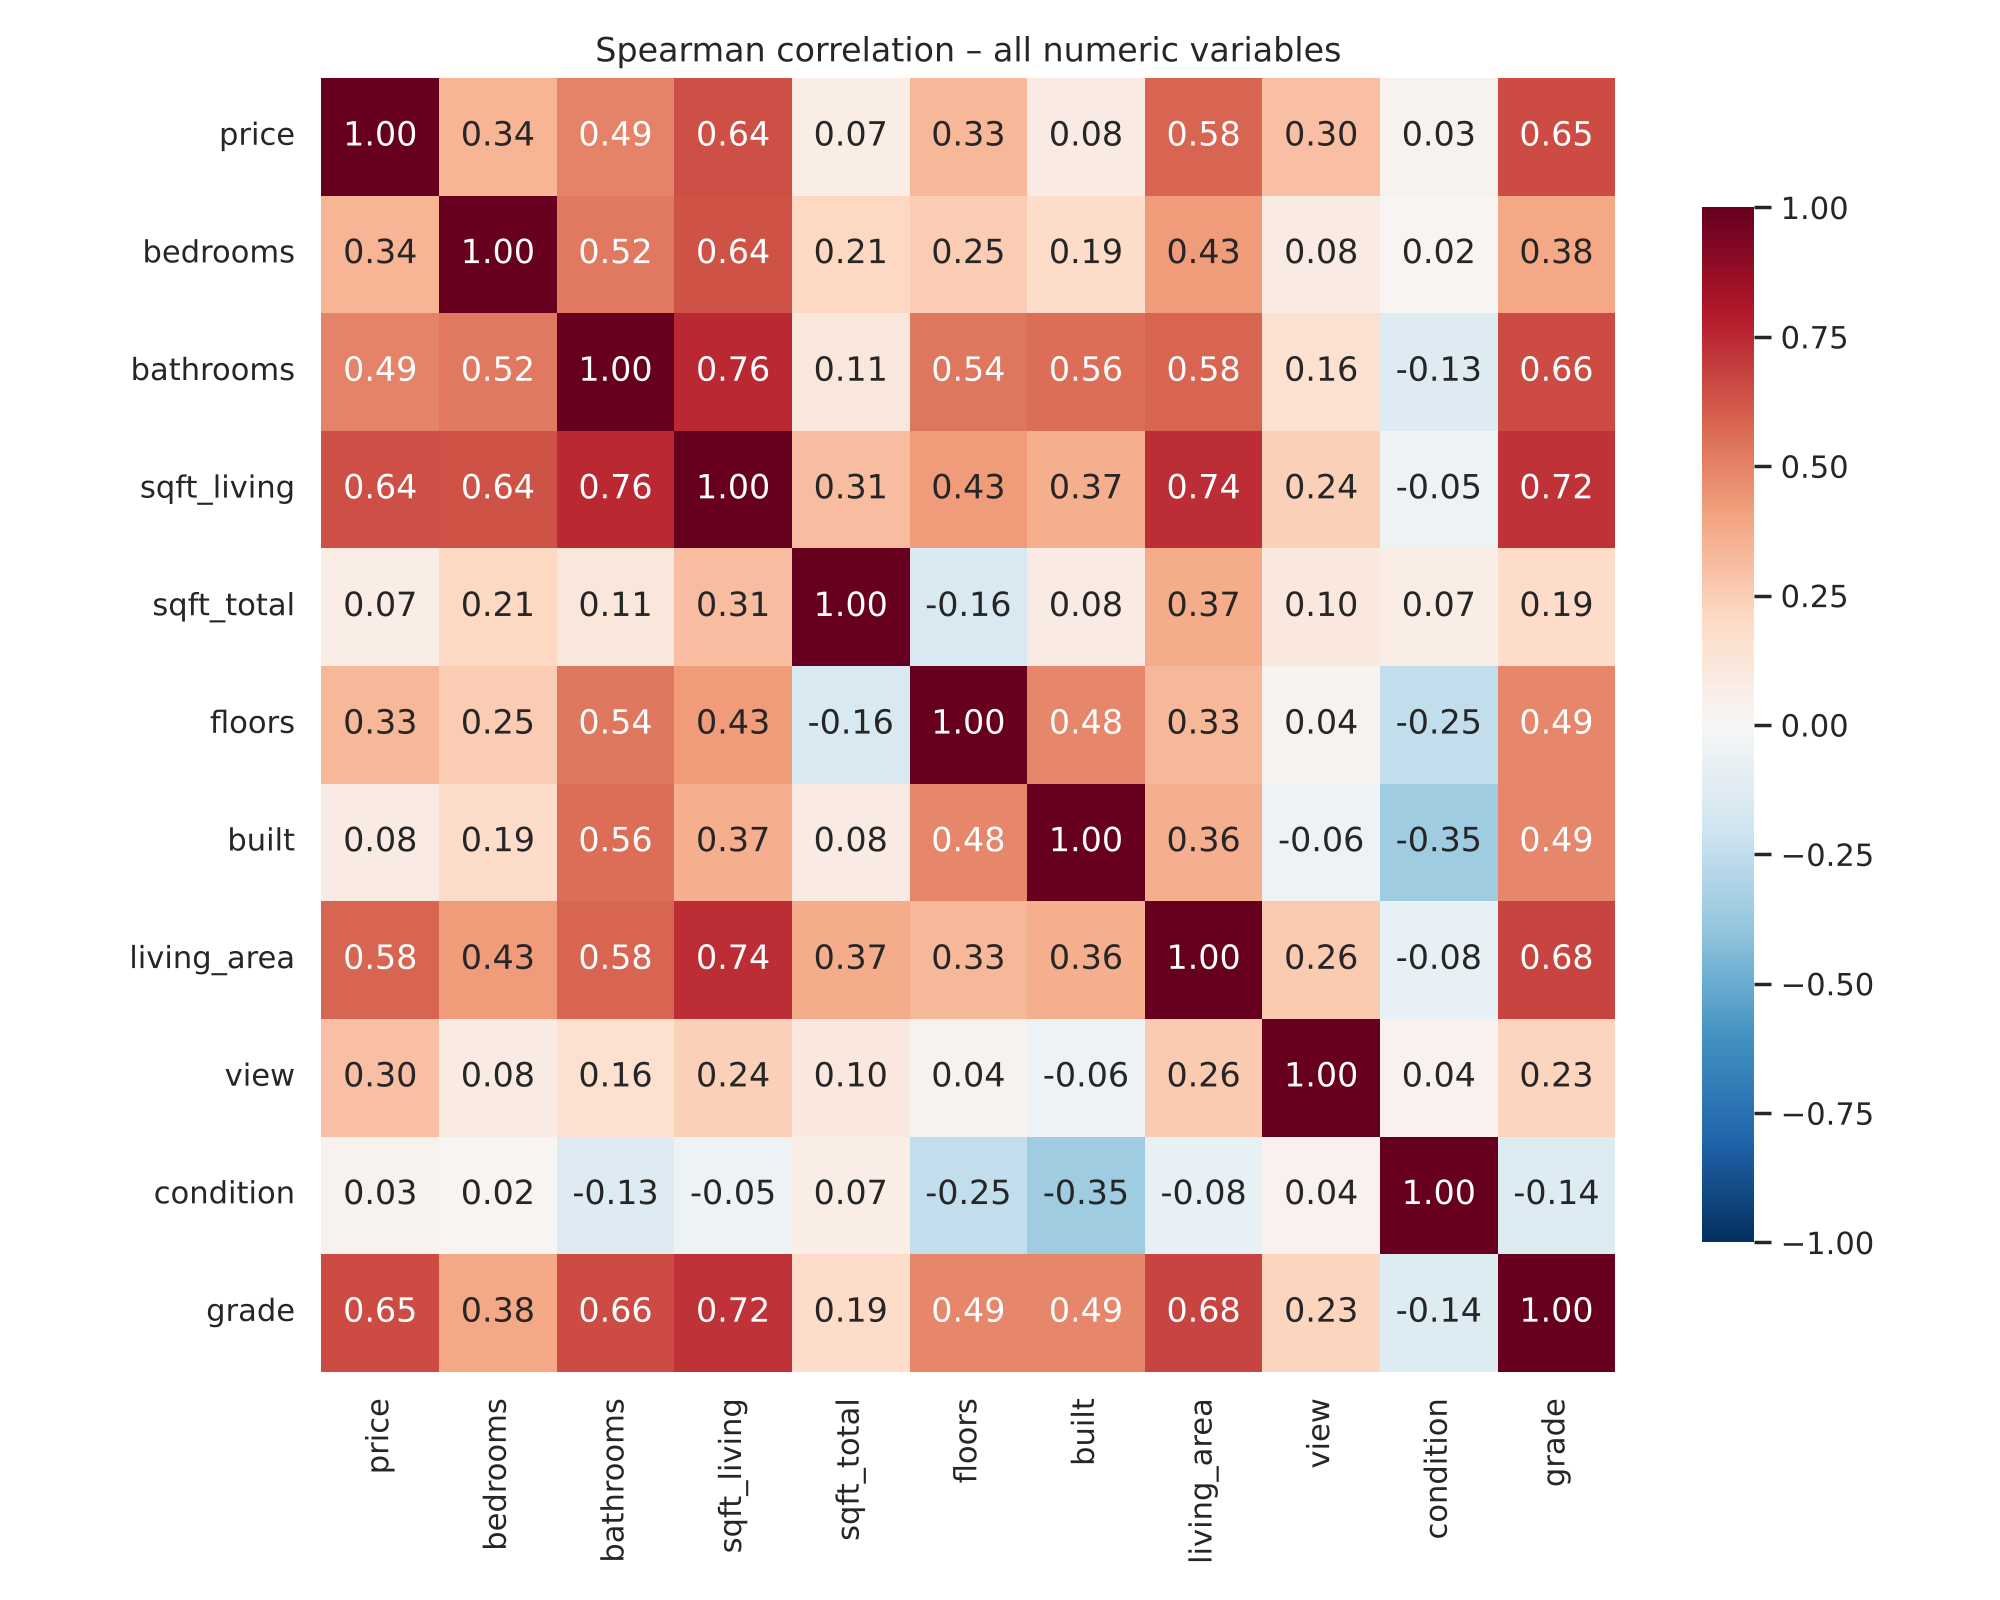

In [ ]:
# Numeric view of the cleaned data (ratings converted to their codes).
numeric_view = clean[["price", "bedrooms", "bathrooms", "sqft_living",
                      "sqft_total", "floors", "built", "living_area"]].join(
    clean[["view", "condition", "grade"]].astype(int))
display(Image(viz.plot_full_correlation(numeric_view)))

**Interpretation:** price is most strongly related to **grade
(ρ = 0.65)** and **living floor space (ρ = 0.64)**, then neighbourhood
floor space (0.58) and bathrooms (0.49). Plot size (0.07), year built
(0.08) and condition (0.03) show almost no direct association. Several
predictors are strongly inter-correlated (e.g. `sqft_living`–`bathrooms`
0.76, `sqft_living`–`grade` 0.72), so their effects overlap – an
important caution for any later regression or machine-learning model
(multicollinearity).

## 8. Investigation 1 – Waterfront properties

**Methods:** medians (robust to skew); **Mann–Whitney U test** (compares
two groups without assuming normality, suitable for very unequal group
sizes); **rank-biserial r** as effect size; and **log-price regressions
with HC3 robust standard errors** to estimate the premium after holding
other attributes constant.

In [ ]:
# Run the waterfront analysis.
wf = analyse_waterfront(clean)
display(wf.summary)
print(f"Mann–Whitney U = {wf.mann_whitney_u:,.0f}, "
      f"p = {wf.mann_whitney_p:.2e}, rank-biserial r = {wf.rank_biserial:.3f}")
print(f"Price per sq ft: U = {wf.ppsf_u:,.0f}, p = {wf.ppsf_p:.2e}")
display(wf.view_crosstab)
display(wf.premiums.style.format("{:.1%}"))

,n,median_price,mean_price,median_sqft_living,median_price_per_sqft,median_grade
waterfront,,,,,,
False,19838,"446,350.00","526,661.02","1,890.00",243.90,7
True,159,"1,365,000.00","1,633,891.77","2,830.00",505.56,9


Mann–Whitney U = 2,785,567, p = 2.25e-62, rank-biserial r = 0.766
Price per sq ft: U = 2,778,296, p = 1.20e-61


view,0,1,2,3,4
waterfront,,,,,
False,17972,316,910,462,178
True,0,1,8,19,131


,premium,ci_low,ci_high
Model,,,
"controls: built, size, grade",74.8%,64.5%,85.8%
+ view rating,40.3%,30.8%,50.5%


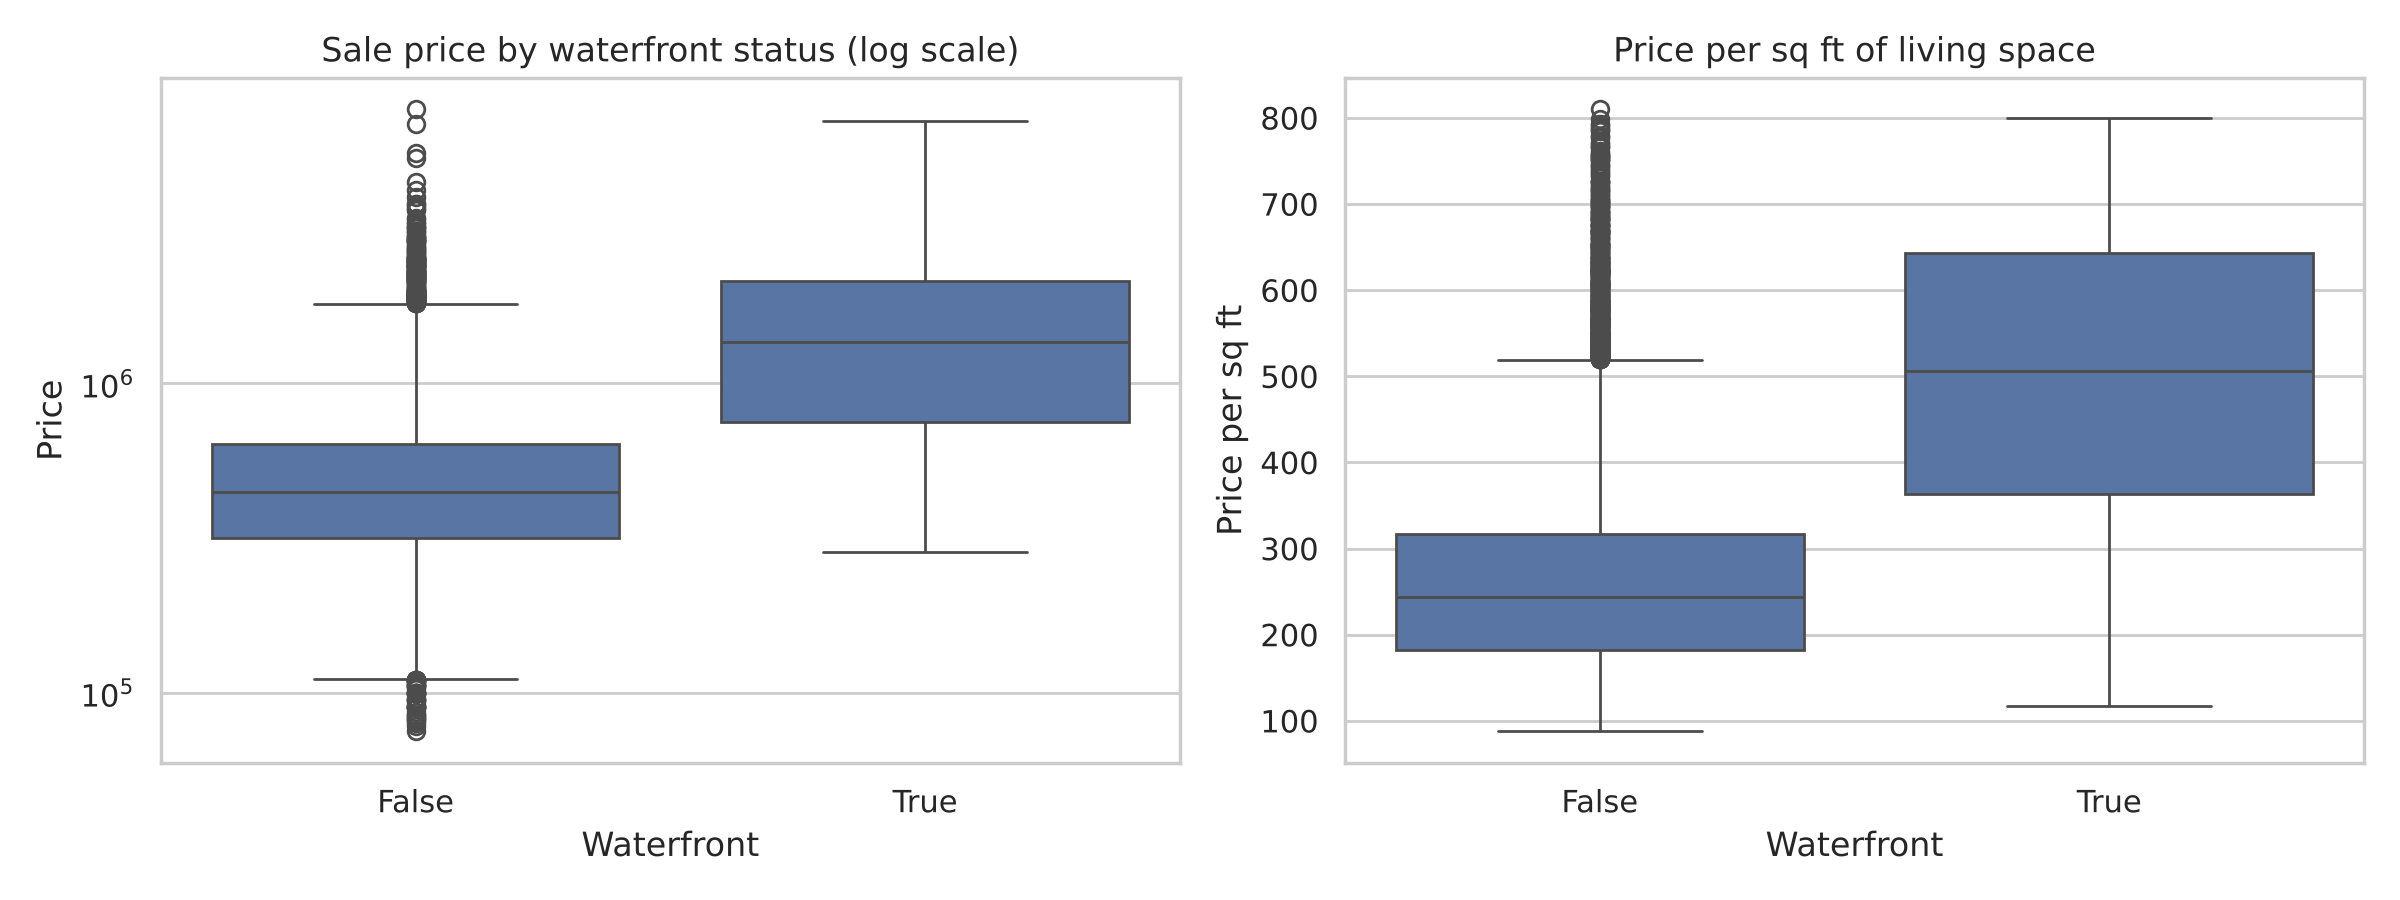

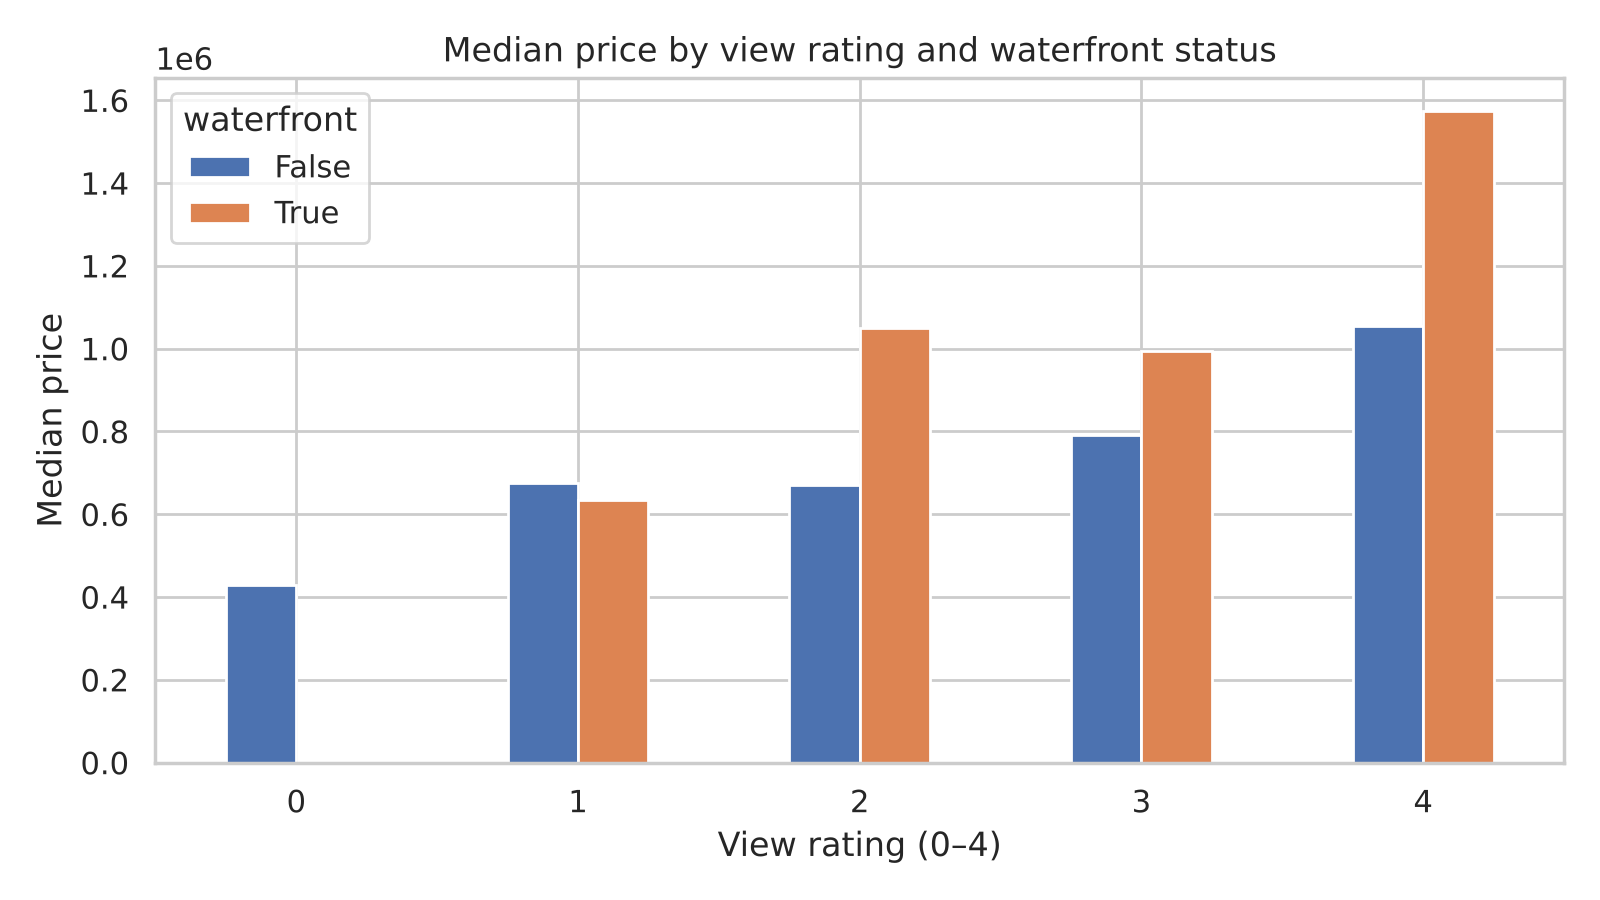

In [ ]:
# Figures 1 and 2.
display(Image(viz.plot_waterfront_boxplots(clean)))
display(Image(viz.plot_view_waterfront(clean)))

**Results**

* The median waterfront price (**1,365,000**) is **3.1 ×** that of other
  properties (446,350). The difference is highly significant
  (p = 2.25 × 10⁻⁶²) with a **large effect (r = 0.77)**: in 88% of random
  pairings the waterfront home is the more expensive.
* But waterfront homes are also larger (median 2,830 vs 1,890 sq ft), of
  higher grade (9 vs 7) and 131 of 159 have the best view, so the raw gap
  **confounds several attributes**.
* Price per sq ft is still 2.1 × higher (505.56 vs 243.90), so the
  premium is not just size.
* Holding age, size and grade constant the premium is **74.8%**
  (95% CI 64.5–85.8%); adding view reduces it to **40.3%**
  (30.8–50.5%).

**Conclusion:** waterfront location carries a substantial independent
premium, but far smaller than the raw threefold gap suggests. With only
159 properties, segment estimates are less precise than market-wide ones.

## 9. Investigation 2 – Floor space

**Methods:** Pearson (linear) and Spearman (monotonic, rank-based)
correlations, distribution check before/after log transformation, and a
log–log regression whose slope is the **price elasticity of floor
space**.

In [ ]:
# Run the floor-space analysis.
fs = analyse_floor_space(clean)
display(fs.pearson.round(3))
display(fs.spearman.round(3))
print(f"Elasticity = {fs.elasticity:.3f}, R² = {fs.r_squared:.3f}")

,price,sqft_living,sqft_total,living_area,built
price,1.00,0.70,0.09,0.60,0.04
sqft_living,0.70,1.00,0.17,0.75,0.32
sqft_total,0.09,0.17,1.00,0.15,0.08
living_area,0.60,0.75,0.15,1.00,0.34
built,0.04,0.32,0.08,0.34,1.00


,price,sqft_living,sqft_total,living_area,built
price,1.00,0.64,0.07,0.58,0.08
sqft_living,0.64,1.00,0.30,0.74,0.37
sqft_total,0.07,0.30,1.00,0.37,0.08
living_area,0.58,0.74,0.37,1.00,0.36
built,0.08,0.37,0.08,0.36,1.00


Elasticity = 0.842, R² = 0.452


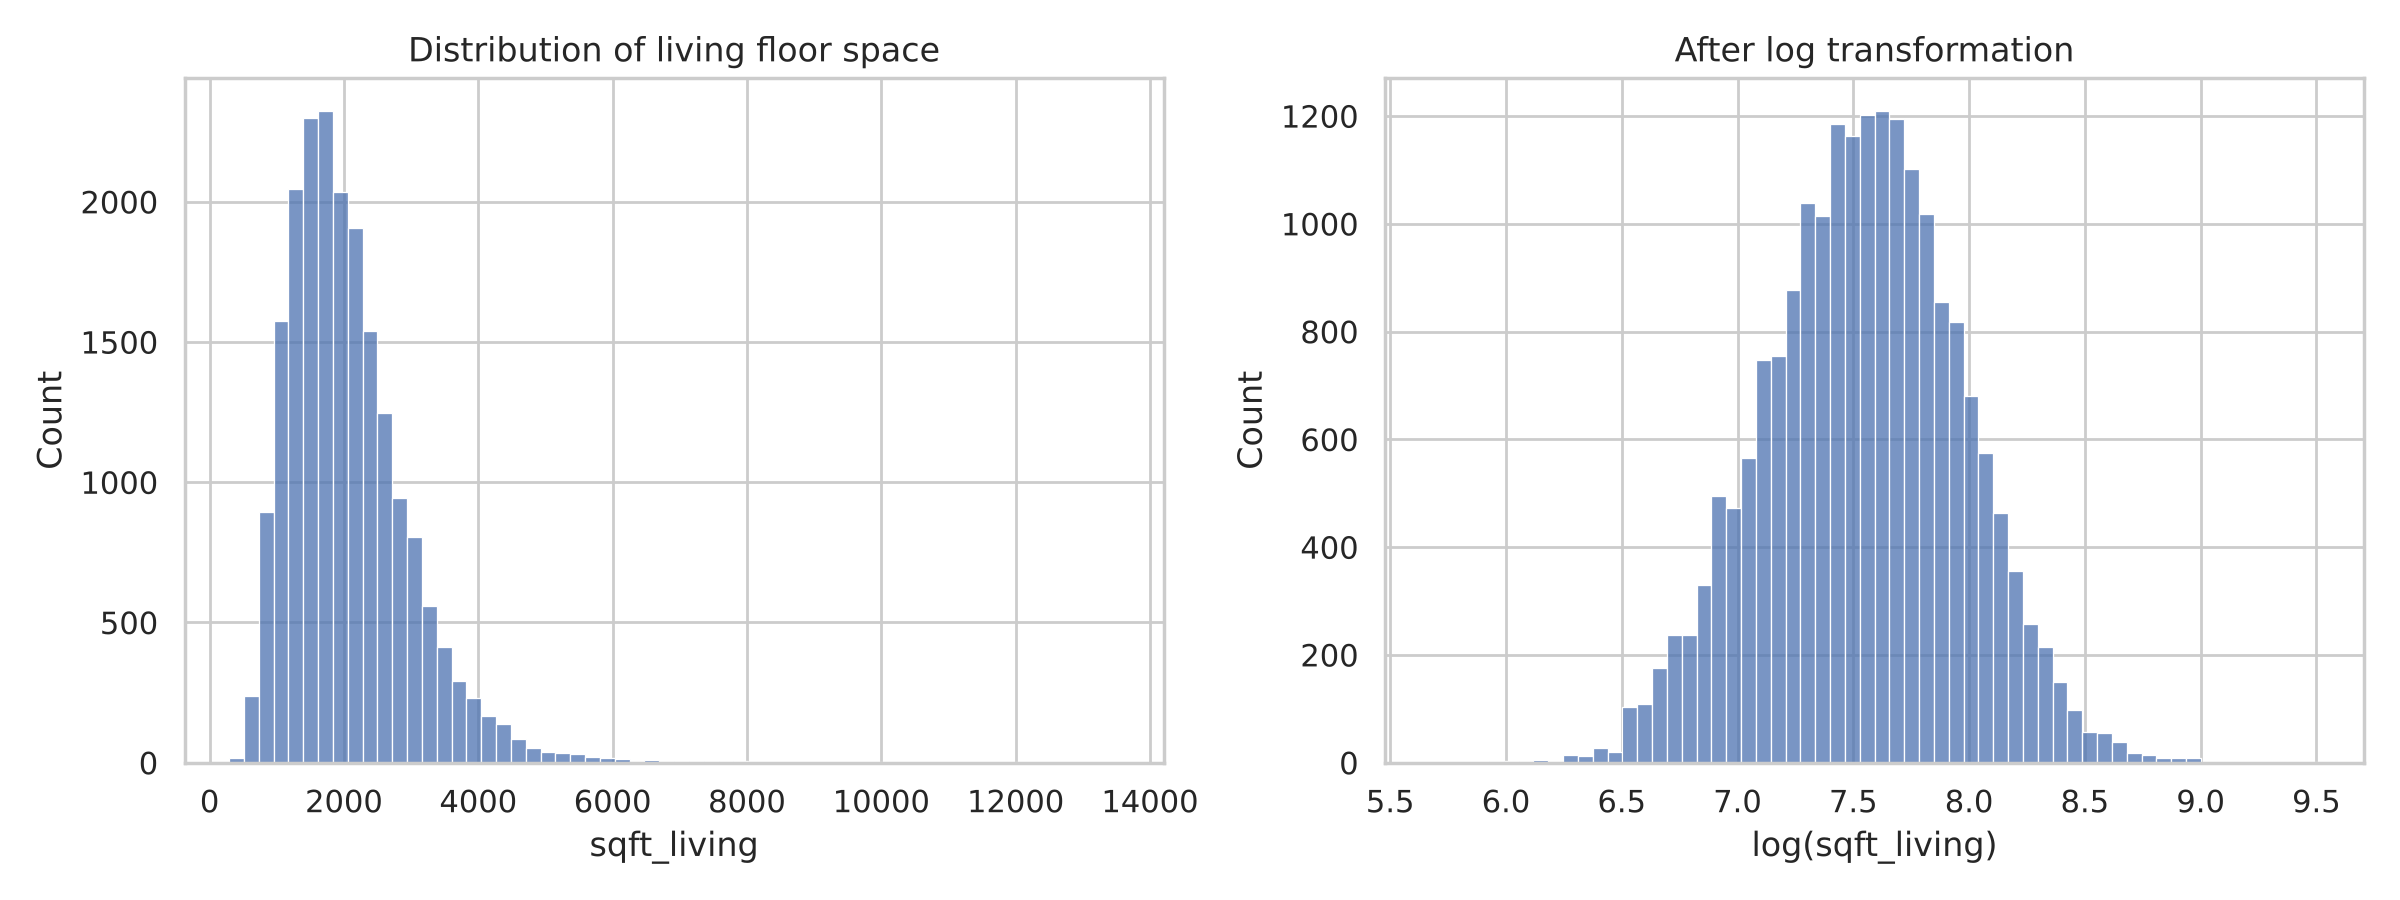

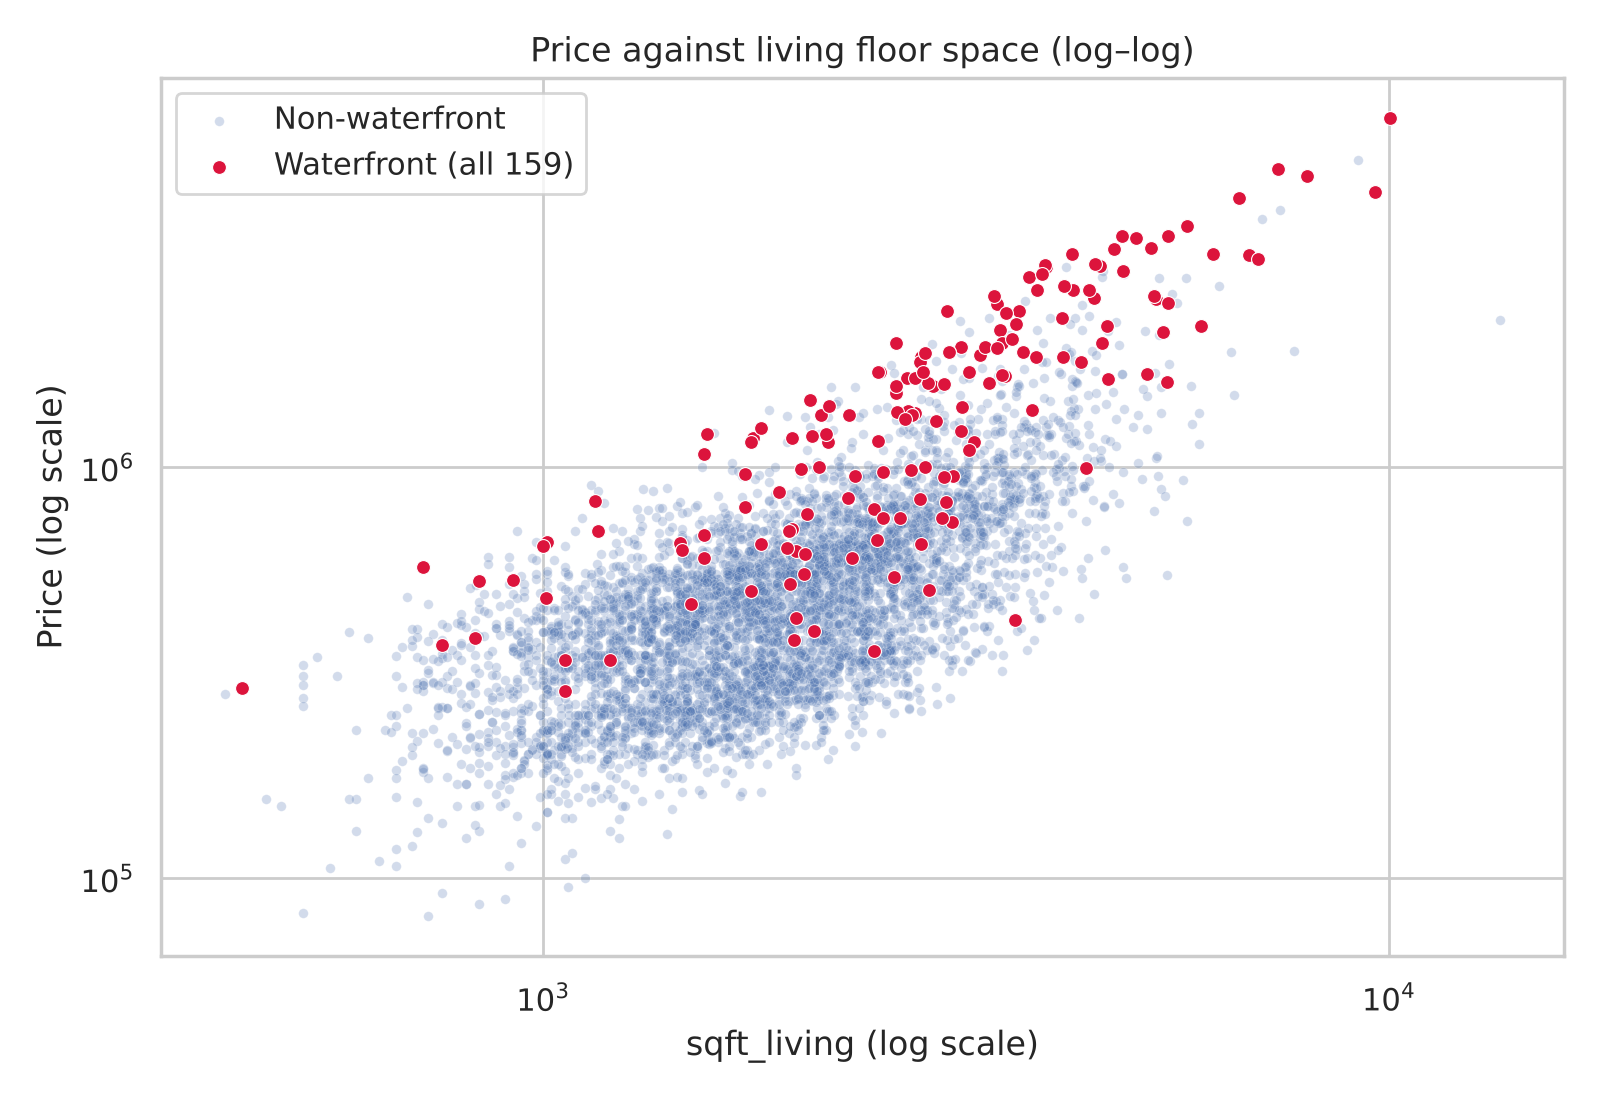

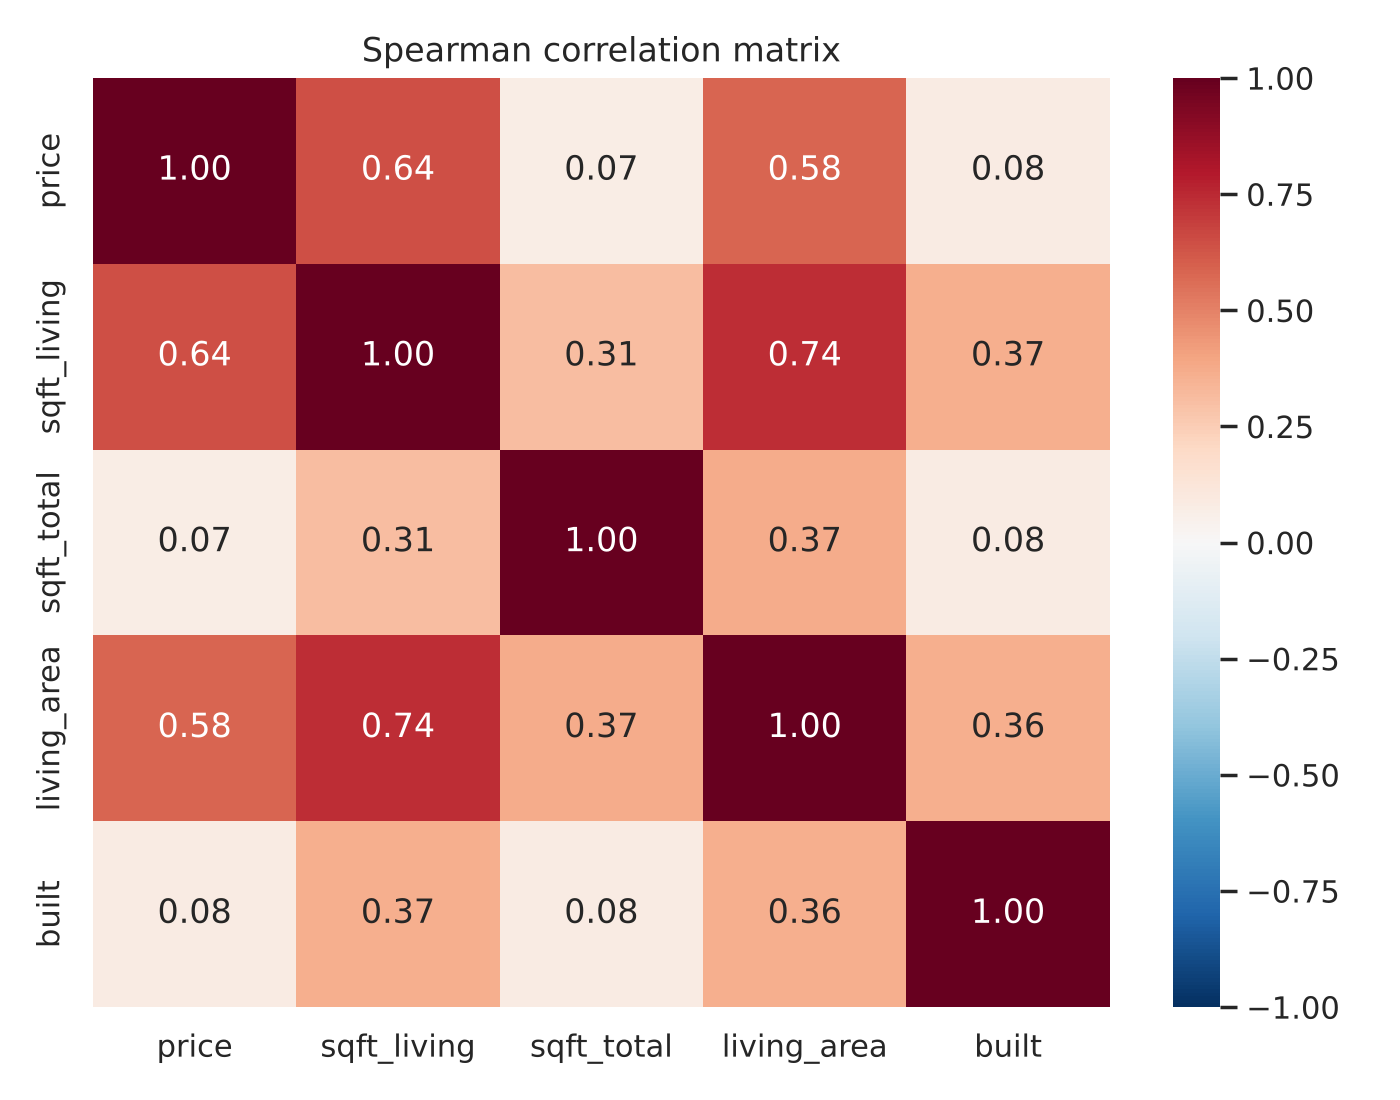

In [ ]:
# Figures 3–5 (one fixed random sample for readable scatter plots).
sample = clean.sample(config.SCATTER_SAMPLE_SIZE,
                      random_state=config.RANDOM_STATE)
display(Image(viz.plot_floor_space_hist(clean)))
display(Image(viz.plot_floor_space_scatter(clean, sample)))
display(Image(viz.plot_correlation_heatmap(fs.spearman)))

**Results**

* Living floor space is the strongest size-related correlate of price:
  **Pearson r = 0.70, Spearman ρ = 0.64**.
* The log–log relationship is close to linear with an **elasticity of
  0.84**: a 1% larger home is associated with a ~0.84% higher price, and
  floor space alone explains **45%** of the variation in log price.
* Neighbourhood floor space (`living_area`, r = 0.60) is highly collinear
  with `sqft_living` (ρ = 0.74) and adds little independent information.
* Plot size is barely related to price (r = 0.09): buyers appear to pay
  for interior space rather than land (an association, not proof).
* In the scatter plot, waterfront homes sit above the main cloud at every
  size – consistent with Investigation 1.

## 10. Investigation 3 – Is `built` correlated with price?

**Methods:** Pearson and Spearman correlation; medians by decade to
reveal non-linear patterns; three regressions that add controls step by
step to test for confounding.

In [ ]:
# Run the year-built analysis.
bp = analyse_built_price(clean)
print(f"Pearson r = {bp.pearson_r:.3f} (p = {bp.pearson_p:.2e}); "
      f"Spearman rho = {bp.spearman_rho:.3f} (p = {bp.spearman_p:.2e}); "
      f"r² = {bp.pearson_r ** 2:.4f}")
display(bp.decade_table)
display(bp.model_table.style.format("{:.4f}"))

Pearson r = 0.040 (p = 1.18e-08); Spearman rho = 0.081 (p = 8.77e-31); r² = 0.0016


,n,median_price,median_sqft,median_ppsf
decade_built,,,,
1900,645,"550,000.00","1,610.00",350.54
1910,805,"510,000.00","1,590.00",333.33
1920,1189,"535,000.00","1,630.00",337.40
1930,526,"479,000.00","1,640.00",314.79
1940,1759,"387,500.00","1,370.00",287.50
1950,2450,"400,000.00","1,630.00",253.66
1960,2654,"380,000.00","1,835.00",214.75
1970,2280,"437,500.00","2,040.00",218.76
1980,2279,"450,000.00","2,060.00",231.25


,built coef,% per decade,95% CI low,95% CI high,R²
Model,,,,,
M1: built only,0.0011,1.1374,0.0009,0.0014,0.0037
M2: + floor space,-0.0038,-3.7273,-0.0040,-0.0036,0.4882
"M3: + grade, waterfront",-0.0058,-5.6171,-0.0060,-0.0056,0.6289


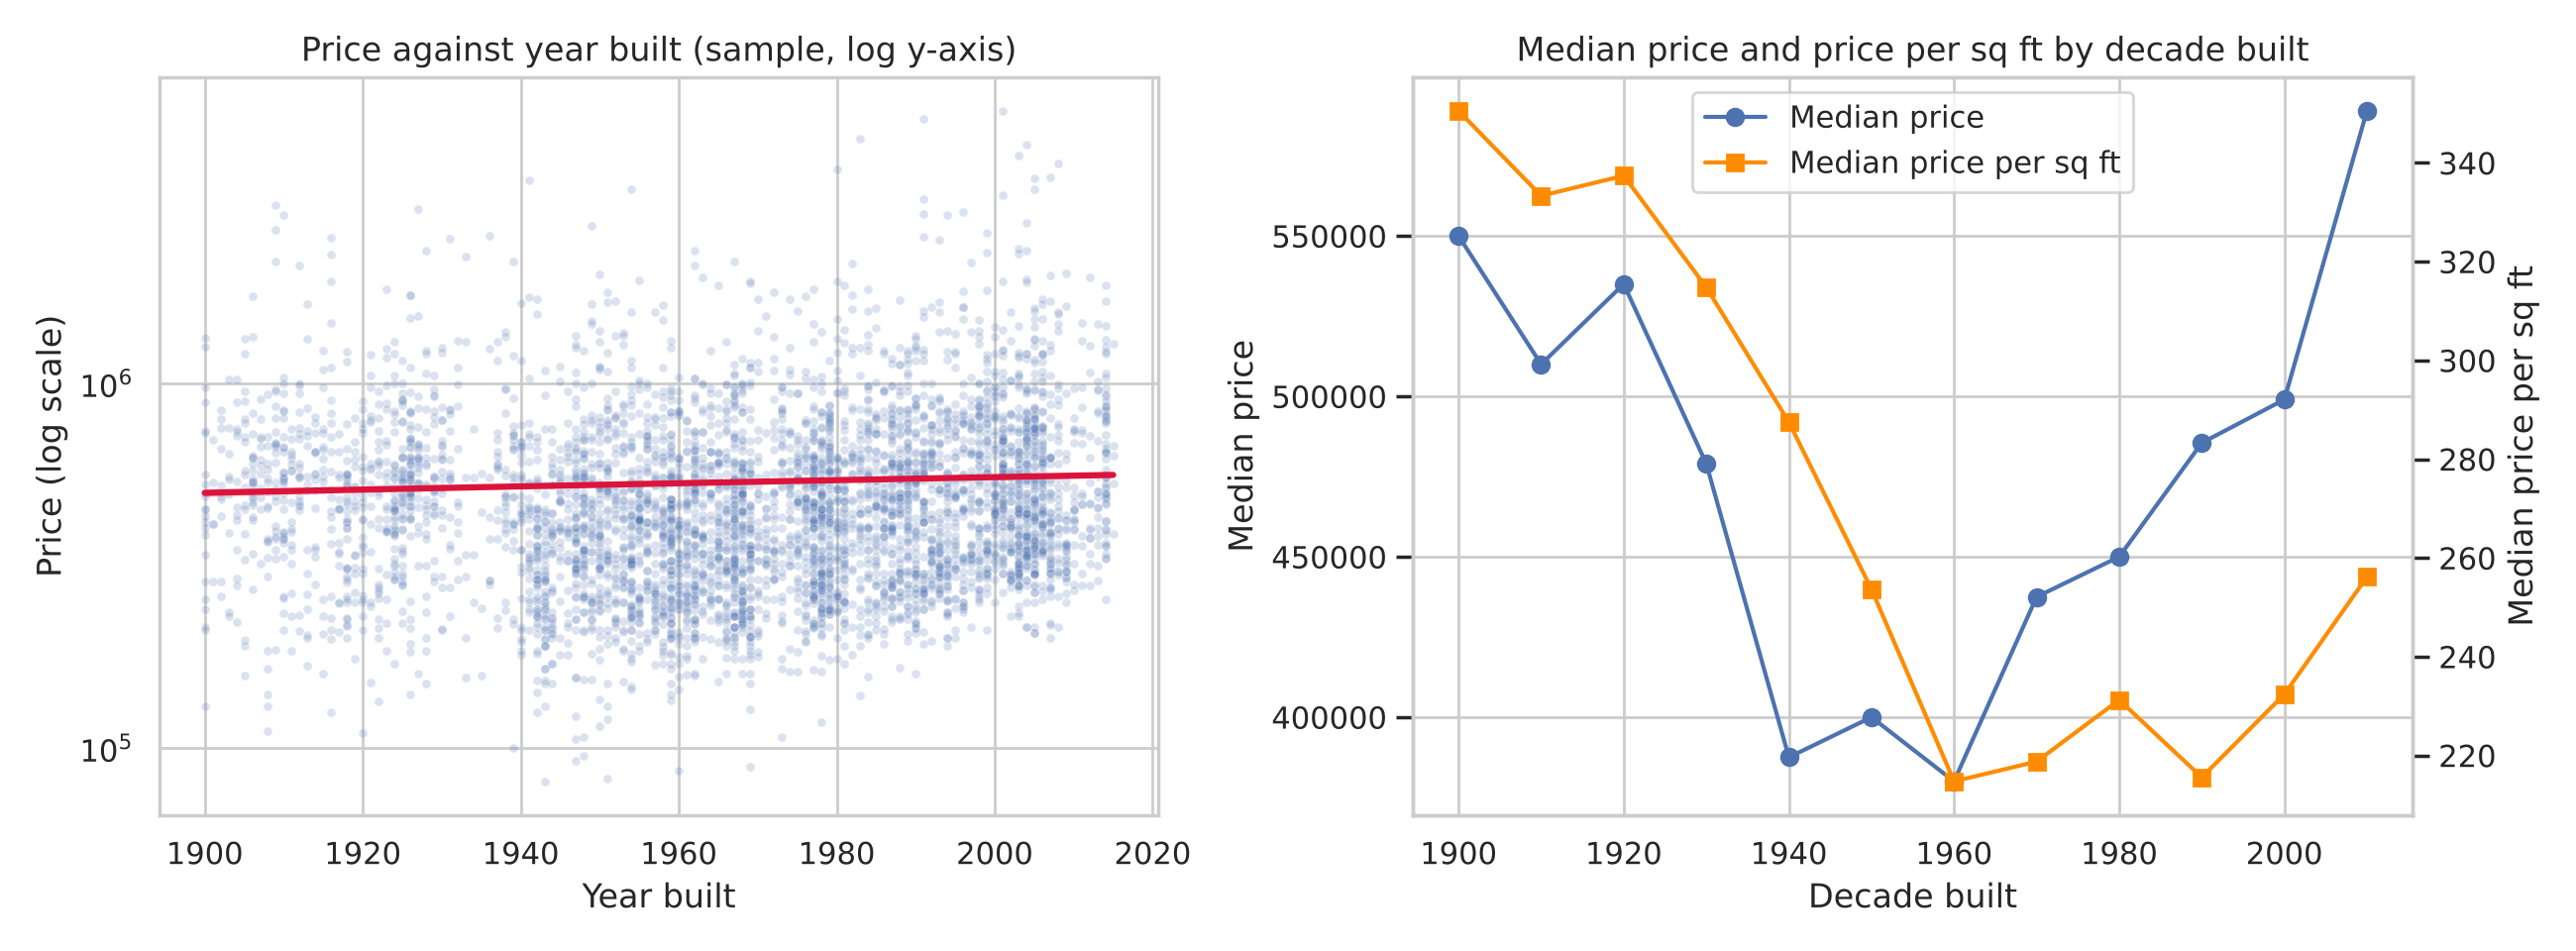

In [ ]:
# Figure 6.
display(Image(viz.plot_built_price(clean, sample, bp.decade_table)))

**Results**

* The direct correlation is **negligible: r = 0.040, ρ = 0.081,
  r² = 0.0016** (0.16% of variance). It is "significant" only because
  n is large – statistical significance is not practical importance.
* Median prices by decade are **U-shaped**: 550,000 (1900s) → 380,000
  (1960s) → 589,000 (2010s). A single linear coefficient cannot describe
  this.
* Newer homes are larger (median 1,610 → 2,450 sq ft) while price per
  sq ft falls from 350.54 to 215.57 (1990s).
* Regression: `built` alone +1.1% per decade; adding floor space flips
  the sign to **−3.7%**; adding grade and waterfront gives **−5.6% per
  decade** (95% CI excludes 0, R² = 0.63).

**Conclusion:** there is no meaningful *direct* correlation. Age and size
are correlated (ρ = 0.37), so the size effect masks a negative
conditional association: at equal size and quality, older homes sell
for more – possibly because of location or period character, which the
data cannot confirm (no location variable).

## 11. Save artifacts

**What happens:** the cleaned dataset and all result tables are written to
`artifacts/` (figures were saved there when they were drawn), so the
report and any later modelling use exactly these outputs.

In [ ]:
# Persist the cleaned data and the main result tables.
config.CLEAN_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
clean.to_csv(config.CLEAN_DATA_PATH, index=False)
outputs = {
    "01_initial_statistics.csv": initial_stats,
    "05_before_after.csv": before_after_comparison(df, clean),
    "06_waterfront_summary.csv": wf.summary,
    "07_waterfront_premiums.csv": wf.premiums,
    "09_spearman_matrix.csv": fs.spearman,
    "10_decade_medians.csv": bp.decade_table,
    "11_built_models.csv": bp.model_table,
}
for name, table in outputs.items():
    save_table(table, config.TABLES_DIR / name)
print("Saved", len(outputs), "tables and the cleaned dataset to",
      config.ARTIFACTS_DIR.relative_to(PROJECT_ROOT))

Saved 7 tables and the cleaned dataset to artifacts


## 12. Summary, limitations and next steps

### Key findings
1. **Floor space is the dominant driver of price** (r = 0.70,
   elasticity 0.84, 45% of log-price variance); grade is equally
   important (ρ = 0.65).
2. **Waterfront homes form a premium segment**: 3.1 × the median price,
   but only ~40% after controlling for size, grade, age and view.
3. **Year built is not useful on its own** (r = 0.04); its effect appears
   only conditionally (−5.6% per decade newer at equal size and quality).

### Limitations
* No data dictionary – meanings of `sqft_total`, `living_area` and the
  grade scale are inferred.
* The data structure matches the public King County (USA) house-sales
  dataset, so prices may be in USD and describe that market – provenance
  must be confirmed.
* No sale date → no time trends or forecasting from this data.
* No location variable → location effects are unobserved confounders.
* All results are associations, not causal effects.

### Next steps (towards a predictive model)
* Use `log_price` as the target and `log_sqft_living`, `grade`, `view`,
  `waterfront`, `bathrooms` and `built` (with a non-linear term) as
  candidate features.
* Handle multicollinearity (e.g. regularised regression) and compare with
  tree-based models (gradient boosting) using k-fold cross-validation.
* Obtain sale dates and postcodes before attempting market forecasting.